# Introduction to Optimization: Max and Min

**Optimization** = find the input where a function is smallest (minimum) or largest (maximum).

| | exact (SymPy) | numerical (NumPy / SciPy) |
|---|---|---|
| **one variable** $f(x)$ on $[a, b]$ | solve $f'(x) = 0$, compare with endpoints | grid search, `minimize_scalar` |
| **several variables** $f(x, y)$ | solve $\nabla f = \mathbf{0}$, Hessian test | grid search, `minimize` |

**Maximize = minimize the negative:** $\max f = -\min(-f)$. The numerical tools only minimize.

In [23]:
import sympy as sp
import numpy as np
from scipy.optimize import minimize_scalar, minimize
import matplotlib.pyplot as plt
from IPython.display import display

## Part A. One variable

To find the max and min of $f$ on $[a, b]$:

1. Find the **critical points**: solve $f'(x) = 0$ and keep those in $[a, b]$.
2. Evaluate $f$ at the critical points **and at the endpoints** $a$, $b$.
3. The largest value is the max; the smallest is the min.

**Second derivative test** at a critical point $x_0$: $f''(x_0) > 0$ → local min; $f''(x_0) < 0$ → local max.

**Example.** $f(x) = x^3 - 3x$ on $[-\tfrac32, 3]$.

In [24]:
x = sp.symbols("x")
f = x**3 - 3*x
a, b = sp.Rational(-3, 2), 3

df = sp.diff(f, x)
crit = sp.solve(df, x)
print("f'(x) =", df, "   critical points:", crit)

for p in crit:
    print(f"x = {p}:  f = {f.subs(x, p)},  f'' = {sp.diff(f, x, 2).subs(x, p)}")
for p in [a, b]:
    print(f"endpoint x = {p}:  f = {f.subs(x, p)}")

f'(x) = 3*x**2 - 3    critical points: [-1, 1]
x = -1:  f = 2,  f'' = -6
x = 1:  f = -2,  f'' = 6
endpoint x = -3/2:  f = 9/8
endpoint x = 3:  f = 18


- $x = -1$: local max ($f'' < 0$), $f = 2$.
- $x = 1$: local min ($f'' > 0$), $f = -2$ → **the min**.
- Endpoint $x = 3$: $f = 18$ → **the max**. The local max at $x = -1$ is not the max on the interval.

**NumPy: grid search.** Evaluate $f$ at many points and pick the smallest/largest value.

min: x = 1.0019999999999998   f = -1.999987992
max: x = 3.0   f = 18.0


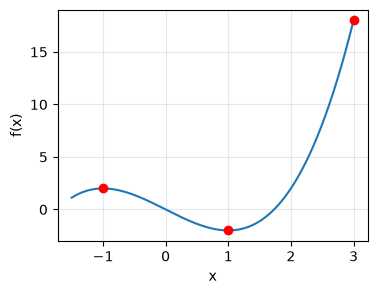

In [25]:
xs = np.linspace(-1.5, 3, 1001)
fx = xs**3 - 3*xs
print("min: x =", xs[np.argmin(fx)], "  f =", fx.min())
print("max: x =", xs[np.argmax(fx)], "  f =", fx.max())

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(xs, fx)
ax.plot([-1, 1, 3], [2, -2, 18], "ro")
ax.set_xlabel("x"); ax.set_ylabel("f(x)"); ax.grid(alpha=0.3)
plt.show()

**SciPy: `minimize_scalar`** searches inside $[a, b]$. To maximize, minimize $-f$.

**Caution:** it finds a **local** min and may miss the endpoints.

In [26]:
fn = lambda t: t**3 - 3*t

res = minimize_scalar(fn, bounds=(-1.5, 3), method="bounded")
print("min:  x =", res.x, "  f =", res.fun)

res = minimize_scalar(lambda t: -fn(t), bounds=(-1.5, 3), method="bounded")
print("max:  x =", res.x, "  f =", -res.fun, "   <- local max only; the true max is at x = 3")

min:  x = 0.9999992918200414   f = -1.9999999999984954
max:  x = -1.0000015400115538   f = 1.999999999992885    <- local max only; the true max is at x = 3


## Part B. Several variables

For $f(x, y)$:

1. **Critical points:** solve $\nabla f = \mathbf{0}$, i.e. $f_x = 0$ and $f_y = 0$ together.
2. **Hessian test.** The Hessian is the matrix of second derivatives
$$ H = \begin{pmatrix} f_{xx} & f_{xy} \\ f_{xy} & f_{yy} \end{pmatrix}, \qquad
\begin{cases} \det H > 0,\ f_{xx} > 0 & \text{local min} \\ \det H > 0,\ f_{xx} < 0 & \text{local max} \\ \det H < 0 & \text{saddle point (neither)} \\ \det H = 0 & \text{test fails} \end{cases} $$

**Example.** $f(x, y) = x^2 + 2y^2 - 2xy - 2x$.

In [27]:
x, y = sp.symbols("x y")
f = x**2 + 2*y**2 - 2*x*y - 2*x

grad = [sp.diff(f, x), sp.diff(f, y)]
print("gradient:", grad)
crit = sp.solve(grad, [x, y], dict=True)
print("critical points:", crit)

H = sp.hessian(f, (x, y))
display(H)
for p in crit:
    Hp = H.subs(p)
    print(p, "  f =", f.subs(p), "  det H =", Hp.det(), "  f_xx =", Hp[0, 0])

gradient: [2*x - 2*y - 2, -2*x + 4*y]
critical points: [{x: 2, y: 1}]


Matrix([
[ 2, -2],
[-2,  4]])

{x: 2, y: 1}   f = -2   det H = 4   f_xx = 2


$\det H = 4 > 0$ and $f_{xx} = 2 > 0$: a **minimum** at $(2, 1)$ with $f = -2$.

**A saddle point.** $g(x, y) = x^2 - y^2$ has $\nabla g = \mathbf{0}$ at the origin, but it goes up along $x$ and down along $y$: neither a max nor a min.

In [28]:
g = x**2 - y**2
print("critical points:", sp.solve([sp.diff(g, x), sp.diff(g, y)], [x, y], dict=True))
print("det H =", sp.hessian(g, (x, y)).det())

critical points: [{x: 0, y: 0}]
det H = -4


**NumPy: picture and grid search.** `np.meshgrid` makes a grid of $(x, y)$ points. Two ways to picture $f$:

- **contour plot** (`ax.contour`): the level curves $f = $ const,
- **density plot** (`ax.pcolormesh`): each point coloured by its value of $f$; the **colorbar** (`fig.colorbar`) shows which colour means which value.

`plt.subplots(1, 2)` gives a figure with two axes side by side.

grid min: x = 2.0   y = 1.0   f = -2.0


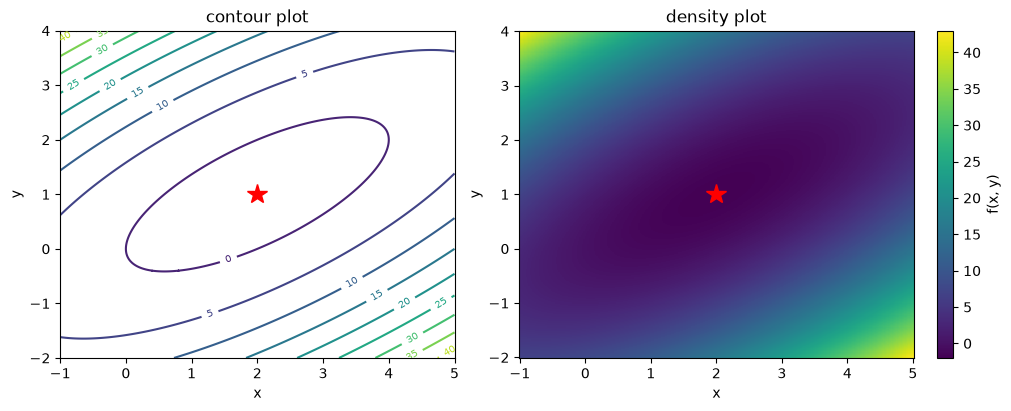

In [29]:
xs = np.linspace(-1, 5, 301)
ys = np.linspace(-2, 4, 301)
X, Y = np.meshgrid(xs, ys)
F = X**2 + 2*Y**2 - 2*X*Y - 2*X

i = np.argmin(F)                              # position in the flattened grid
print("grid min: x =", X.flat[i], "  y =", Y.flat[i], "  f =", F.flat[i])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

cs = ax1.contour(X, Y, F, levels=10, cmap="viridis")
ax1.clabel(cs, fontsize=7)
# fig.colorbar(cs, ax=ax1, label="f(x, y)")
ax1.set_title("contour plot")

pm = ax2.pcolormesh(X, Y, F, cmap="viridis", shading="auto")
fig.colorbar(pm, ax=ax2, label="f(x, y)")
ax2.set_title("density plot")

for ax in (ax1, ax2):
    ax.plot(2, 1, "r*", markersize=15)
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

**SciPy: `minimize(fun, x0)`.** The function takes **one array** `v` holding all the variables: `v[0]` is $x$, `v[1]` is $y$. `x0` is a starting guess. It works the same way for any number of variables. To maximize, minimize $-f$.

In [30]:
fn = lambda v: v[0]**2 + 2*v[1]**2 - 2*v[0]*v[1] - 2*v[0]

res = minimize(fn, x0=[0, 0])
print("x, y =", res.x, "   f =", res.fun)

x, y = [1.99999988 0.99999999]    f = -1.9999999999999867


### Summary

| | SymPy | NumPy / SciPy |
|---|---|---|
| derivative | `sp.diff(f, x)`; second: `sp.diff(f, x, 2)` | |
| critical points, 1 variable | `sp.solve(sp.diff(f, x), x)` | |
| critical points, 2 variables | `sp.solve([f_x, f_y], [x, y], dict=True)` | |
| Hessian | `sp.hessian(f, (x, y))` | |
| grid search | | `np.linspace`, `np.meshgrid`, `np.argmin` |
| plots | | `fig, ax = plt.subplots()`; `ax.contour`, `ax.pcolormesh`, `fig.colorbar` |
| min of $f(x)$ on $[a, b]$ | compare critical points and endpoints | `minimize_scalar(f, bounds=(a, b), method="bounded")` |
| min of $f(x, y)$ | | `minimize(f, x0=[0, 0])` |
| maximize | minimize $-f$ | minimize $-f$ |

## Exercises

Solve with **SymPy** (exact) and with **NumPy/SciPy** (numerical).

**Syntax you will need:**

| task | SymPy | NumPy / SciPy |
|---|---|---|
| variables | `x, y = sp.symbols("x y")` | |
| derivative | `sp.diff(f, x)`, `sp.diff(f, x, 2)` | |
| solve equations | `sp.solve(eqs, [x, y], dict=True)` | |
| substitute | `f.subs(x, 2)`, `f.subs({x: 2, y: 1})` | |
| Hessian | `sp.hessian(f, (x, y))` | |
| matrix entry, transpose | `H[0, 0]`, `H.T` | `H[0, 0]`, `H.T` |
| determinant | `H.det()` | `np.linalg.det(H)` |
| function of one variable | | `fn = lambda t: t**2 - 3*t` |
| function of several variables | | `fn = lambda v: v[0]**2 + v[1]**2` |
| grid of points | | `np.linspace(a, b, 1001)` |
| 2D grid | | `X, Y = np.meshgrid(xs, ys)` |
| position of min / max | | `np.argmin(v)`, `np.argmax(v)` |
| figure with 1 or 2 plots | | `fig, ax = plt.subplots()`, `fig, (ax1, ax2) = plt.subplots(1, 2)` |
| line plot | | `ax.plot(xs, ys)` |
| contour plot | | `cs = ax1.contour(X, Y, F, levels=20)` |
| density plot | | `pm = ax2.pcolormesh(X, Y, F, shading="auto")` |
| colorbar | | `fig.colorbar(pm, ax=ax2)` |
| min of $f(x)$ on $[a, b]$ | | `minimize_scalar(fn, bounds=(a, b), method="bounded")` |
| min of $f(x, y)$ | | `minimize(fn, x0=[0, 0])` |

**Exercise 1 (one variable).** Let $f(x) = x^3 - 6x^2 + 9x$ on $[-1, 5]$.

(a) In **SymPy**, find the critical points and classify them with $f''$. Compare with the endpoints to find the max and min.

(b) Check with **NumPy** on a grid, and with `minimize_scalar`. Does `minimize_scalar` find the true max and min?

In [31]:
# Exercise 1

**Exercise 2 (two variables, minimum).** Let $f(x, y) = x^2 + xy + y^2 - 3x$.

(a) In **SymPy**, find the critical point and the Hessian, and classify the point.

(b) Check with SciPy's `minimize`, starting from $(0, 0)$.

In [32]:
# Exercise 2

**Exercise 3 (two variables, maximum).** Let $f(x, y) = 8x + 4y - 2x^2 - 2xy - y^2$.

(a) In **SymPy**, find the critical point and use the Hessian test to show it is a maximum.

(b) Find the max with SciPy's `minimize` (minimize $-f$). Make a contour plot and a density plot side by side, each with a colorbar, and mark the point.

In [33]:
# Exercise 3